# Project Phase 2 — Statistical Damage Detection

**Course:** CIV E 789 Sensing Techniques and Data Analytics (Fall 2026)  
**Instructor:** Mohammad Talebi-Kalaleh, Ph.D.  
**Group:** 6 (sensors S2, S4, S6, S9, S12, S15, S18, S21, S24)  
**Data:** `phase2_modal_parameters.json` (intact, damage1, damage2; 20 estimates each)

## Contents

0. [Setup](#setup)
1. [Part A: Feature Distribution Analysis](#part-a)
2. [Part B: Single Feature Damage Detection](#part-b)
3. [Part C: Bivariate Analysis](#part-c)
4. [Part D: Feature Fusion and Engineering](#part-d)
5. [Part E: Principal Component Analysis](#part-e)
6. [Part F: Engineering Insights](#part-f)
7. [Use of Generative AI](#ai-note)

<a id="setup"></a>
## 0. Setup

This section loads the data used throughout the project and sets up the common tools. Parts A–E start from the arrays created here, so that all of them work with exactly the same data.

- **0.1** Libraries, paths and helper functions to present tables and figures.
- **0.2** Loading the JSON file and the group 6 sensors.
- **0.3** Extraction of natural frequencies and mode shapes, with automatic checks.

In [1]:
# Google Colab only: mount Google Drive and run from the project folder (does nothing elsewhere)
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

    # Find the project folder wherever it is in the Drive: usual locations first, then a full search
    DRIVE_ROOT = Path('/content/drive')
    PROJECT = 'ProjectPhase2_Group6'
    usual = [f'MyDrive/CIV E 789/{PROJECT}', f'MyDrive/{PROJECT}', f'Shareddrives/*/CIV E 789/{PROJECT}',
             f'.shortcut-targets-by-id/*/CIV E 789/{PROJECT}']
    found = [p for pattern in usual for p in DRIVE_ROOT.glob(pattern)
             if (p / 'phase2_modal_parameters.json').exists()]
    if not found:
        found = [p.parent for p in DRIVE_ROOT.glob(f'**/{PROJECT}/phase2_modal_parameters.json')]
    assert found, f'{PROJECT} folder with phase2_modal_parameters.json not found in Google Drive'
    os.chdir(found[0])
    print('Working folder:', found[0])

### 0.1 Libraries, paths and presentation helpers

- The file `phase2_modal_parameters.json` is searched for first in the notebook folder and, if it is not there, in the parent folder.
- Figures are saved in `figures/part-a/` … `figures/part-e/` and result tables in `results/` (CSV). The folders are created if they do not exist.
- `show_table` places the table caption above the table (**Table N.**) and `show_figure` places the figure caption below the figure (**Figure N.**), both outside the object. `show_figure` also saves the figure in the folder of its part.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Input data: next to this notebook or, if not there, in the parent folder
DATA_FILE = 'phase2_modal_parameters.json'
DATA_PATH = next((p for p in (Path(DATA_FILE), Path('..') / DATA_FILE) if p.exists()), None)
assert DATA_PATH is not None, f'{DATA_FILE} not found next to the notebook or in its parent folder'

# Output folders: one figure folder per part, one folder for result tables
FIG_DIR = Path('figures')
RES_DIR = Path('results')
for part in ['part-a', 'part-b', 'part-c', 'part-d', 'part-e']:
    (FIG_DIR / part).mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


def show_table(df, number, caption, filename=None, precision=4):
    """Show the table caption above the table; optionally save the table as CSV in results/."""
    display(Markdown(f'**Table {number}.** {caption}'))
    display(df.style.format(precision=precision))
    if filename is not None:
        df.to_csv(RES_DIR / filename)


def show_figure(fig, number, caption, part, filename):
    """Save the figure in figures/<part>/, show it and put the caption below it."""
    fig.savefig(FIG_DIR / part / filename, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    display(Markdown(f'**Figure {number}.** {caption}'))

### 0.2 Data loading and group 6 sensors

- The JSON file has two blocks: `scenarios` (data for `intact`, `damage1` and `damage2`) and `metadata` (sampling information, sensors assigned to each group and position of each sensor).
- The group sensors are read from `metadata.sensor_assignments.group_6` instead of being typed by hand, to avoid copying errors.
- Each mode shape is a list of 24 values ordered from S1 to S24, so sensor $S_k$ is at index $k-1$ of the list (Table 1).
- The position of each sensor (`metadata.sensor_positions_m`) will be used as the x-axis of the mode shapes.

In [3]:
with open(DATA_PATH, 'r') as f:
    data = json.load(f)

GROUP = 6
SCENARIOS = ['intact', 'damage1', 'damage2']
MODES = ['mode_1', 'mode_2', 'mode_3']
N_MEAS = data['metadata']['sampling_info']['total_estimates']   # 20 estimates per condition
N_SENSORS_TOTAL = len(data['metadata']['sensor_positions_m'])   # 24 sensors on the bridge

# Sensors assigned to our group, read from the file (not typed by hand)
my_sensors = data['metadata']['sensor_assignments'][f'group_{GROUP}']
SENSOR_IDX = np.array([int(s[1:]) - 1 for s in my_sensors])   # Sk -> list index k - 1
SENSOR_POS = np.array([data['metadata']['sensor_positions_m'][s] for s in my_sensors])   # [m]

sensors_table = pd.DataFrame({'List index': SENSOR_IDX, 'Position (m)': SENSOR_POS},
                             index=pd.Index(my_sensors, name='Sensor'))
show_table(sensors_table, 1, f'Sensors assigned to group {GROUP}, their index in the 24-value lists '
           'and their position along the bridge.', precision=1)

**Table 1.** Sensors assigned to group 6, their index in the 24-value lists and their position along the bridge.

,List index,Position (m)
Sensor,,
S2,1,7.5
S4,3,17.5
S6,5,27.5
S9,8,42.5
S12,11,57.5
S15,14,72.5
S18,17,87.5
S21,20,102.5
S24,23,117.5


### 0.3 Extraction of natural frequencies and mode shapes

The first cell defines the two extraction functions from the assignment starter code (Section 7), with the same names and behaviour: `extract_frequencies(scenario, mode_key)` returns the 20 frequencies of one mode, and `extract_mode_shape(scenario, measurement_idx, mode_key)` returns one mode shape at the 9 group sensors. The second cell uses them to store the data in numpy arrays, one per scenario (Table 2).

**Table 2.** Numpy arrays created in the data extraction.

| Array | Size | Content |
|---|---|---|
| `freqs[scenario]` | 20 × 3 | measurements × modes, natural frequency in Hz |
| `shapes[scenario]` | 3 × 20 × 9 | modes × measurements × group 6 sensors |

- **Assumption:** value $i$ of each frequency list and `measurement_i` of the mode shapes come from the same 30-s segment. The assignment does not state this explicitly. It does not matter for Parts A and B, which analyse each feature separately, but Parts C, D and E combine several features of the same measurement into a single point.
- Measurements are read as `measurement_1` … `measurement_20` in numeric order, not in the order of the JSON keys.
- Mode shapes are not normalized again: they are already scaled to a maximum of 1 over the 24 sensors. The MAC does not depend on scale, so this does not affect it.
- The checks (`assert`) stop the notebook if a measurement is missing, if a mode shape does not have 24 values, or if there are missing values (NaN).

In [4]:
# Extraction functions from the starter code (same names and behaviour)

# Extract frequencies for a scenario
def extract_frequencies(scenario, mode_key='mode_1'):
    return np.array(data['scenarios'][scenario]['natural_frequencies'][mode_key])


# Extract mode shape at assigned sensors
def extract_mode_shape(scenario, measurement_idx, mode_key='mode_1'):
    mode_data = data['scenarios'][scenario]['mode_shapes'][mode_key][f'measurement_{measurement_idx}']
    # mode_data is a list of 24 values ordered S1..S24, so S1 -> index 0
    return np.array([mode_data[int(s[1:]) - 1] for s in my_sensors])

In [5]:
# freqs[scenario]:  (N_MEAS, 3) array -> measurements x modes, in Hz
# shapes[scenario]: (3, N_MEAS, 9) array -> modes x measurements x our 9 sensors
# Measurements are read as measurement_1 ... measurement_20 (numeric order), so row i of
# freqs and measurement i of shapes refer to the same 30-s segment.
freqs = {}
shapes = {}
for sc in SCENARIOS:
    freqs[sc] = np.column_stack([extract_frequencies(sc, m) for m in MODES])
    shapes[sc] = np.array([[extract_mode_shape(sc, i, m) for i in range(1, N_MEAS + 1)]
                           for m in MODES])

# Sanity checks on the raw file and on the extracted arrays
for sc in SCENARIOS:
    for m in MODES:
        assert len(data['scenarios'][sc]['natural_frequencies'][m]) == N_MEAS
        mode_shapes = data['scenarios'][sc]['mode_shapes'][m]
        assert set(mode_shapes) == {f'measurement_{i}' for i in range(1, N_MEAS + 1)}
        assert all(len(v) == N_SENSORS_TOTAL for v in mode_shapes.values())
    assert freqs[sc].shape == (N_MEAS, len(MODES))
    assert shapes[sc].shape == (len(MODES), N_MEAS, len(my_sensors))
    assert np.isfinite(freqs[sc]).all() and np.isfinite(shapes[sc]).all()
print('Extraction checks passed: '
      f'{len(SCENARIOS)} scenarios x {len(MODES)} modes x {N_MEAS} measurements x {len(my_sensors)} sensors')

Extraction checks passed: 3 scenarios x 3 modes x 20 measurements x 9 sensors


In [6]:
# One table per scenario: rows = modes, columns = measurements
for t, sc in enumerate(SCENARIOS, start=3):
    freq_table = pd.DataFrame(freqs[sc].T,
                              index=pd.Index([f'f{k + 1} (Hz)' for k in range(len(MODES))], name='Mode'),
                              columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(freq_table, t, f'Natural frequencies of modes 1–3 for each of the 20 measurements, {sc} scenario.',
               precision=3)

**Table 3.** Natural frequencies of modes 1–3 for each of the 20 measurements, intact scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.063,1.274,1.259,0.973,1.154,1.276,1.103,0.993,1.141,1.096,1.093,1.141,1.059,1.019,1.217,1.091,1.095,1.091,1.327,1.402
f2 (Hz),2.847,3.404,3.253,2.537,3.052,3.345,2.811,2.669,3.038,2.886,2.907,2.943,2.877,2.696,3.303,2.875,2.801,2.855,3.450,3.733
f3 (Hz),4.083,4.945,4.795,3.677,4.330,4.912,4.000,3.792,4.395,4.168,4.154,4.244,4.118,3.935,4.703,4.085,4.164,4.126,4.961,5.368


**Table 4.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage1 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.131,1.191,1.262,1.052,0.994,1.232,1.041,1.096,1.232,1.177,1.190,1.063,1.066,0.940,1.104,1.098,1.154,1.082,0.988,0.966
f2 (Hz),2.777,2.962,3.067,2.769,2.429,3.077,2.727,2.860,3.151,3.105,3.056,2.678,2.714,2.431,2.885,2.778,2.852,2.790,2.549,2.569
f3 (Hz),4.284,4.506,4.717,4.059,3.738,4.581,4.144,4.242,4.728,4.454,4.568,3.997,3.998,3.595,4.202,4.026,4.319,4.054,3.708,3.906


**Table 5.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage2 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.212,1.052,1.095,1.054,1.064,1.035,1.152,1.236,0.943,1.238,0.980,0.991,1.307,1.083,1.004,0.981,1.159,1.096,0.917,1.255
f2 (Hz),2.793,2.557,2.841,2.533,2.621,2.488,2.937,2.989,2.382,3.058,2.453,2.525,3.302,2.712,2.544,2.555,2.955,2.681,2.338,3.016
f3 (Hz),4.491,4.064,4.379,3.992,3.980,4.107,4.360,4.687,3.601,4.589,3.684,3.939,4.851,4.118,3.926,3.802,4.416,4.161,3.572,4.662


<a id="part-a"></a>
## Part A: Feature Distribution Analysis (25 pts)

### A1. Natural Frequency Distributions (8 pts)

### A2. Mode Shape Visualization (9 pts)

### A3. Modal Assurance Criterion (MAC) Distributions (8 pts)

<a id="part-b"></a>
## Part B: Single Feature Damage Detection (20 pts)

### B1. Z-Score Anomaly Detection (10 pts)

### B2. Wasserstein Distance Analysis (7 pts)

### B3. Feature Sensitivity Ranking (3 pts)

<a id="part-c"></a>
## Part C: Bivariate Analysis (20 pts)

### C1. Joint Distribution Visualization (7 pts)

Se analizan dos pares de variables: $(f_1, f_2)$ y $(\mathrm{MAC}_1, \mathrm{MAC}_2)$.

Para calcular el Modal Assurance Criterion (MAC) se utilizó la siguiente ecuación:

$$
\mathrm{MAC} = \frac{\left(\boldsymbol{\phi}_{ref}^{T}\,\boldsymbol{\phi}_{test}\right)^{2}}{\left(\boldsymbol{\phi}_{ref}^{T}\boldsymbol{\phi}_{ref}\right)\left(\boldsymbol{\phi}_{test}^{T}\boldsymbol{\phi}_{test}\right)}
\tag{1}
$$

Donde:

- $\boldsymbol{\phi}_{ref}$: forma modal de referencia, igual al promedio de las 20 mediciones del escenario intacto (9 valores, uno por sensor).
- $\boldsymbol{\phi}_{test}$: forma modal de una medición (9 valores).
- $\boldsymbol{\phi}^{T}\boldsymbol{\phi}$: producto punto, es decir, se multiplica sensor por sensor y se suman los resultados.

**Table 6.** MAC of modes 1 and 2 for each of the 20 measurements, intact scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,1.0000,0.9999,0.9999,0.9999,0.9999,1.0000,0.9998,0.9996,0.9999,0.9999,0.9993,0.9999,0.9998,1.0000,0.9996,0.9999,0.9992,1.0000,0.9999,0.9999
MAC2,0.9994,0.9991,0.9994,0.9997,0.9952,0.9924,0.9980,0.9987,0.9991,0.9973,0.9991,0.9995,0.9997,0.9977,0.9987,0.9996,0.9985,0.9991,0.9980,0.9994


**Table 7.** MAC of modes 1 and 2 for each of the 20 measurements, damage1 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9996,0.9994,0.9990,0.9995,0.9992,0.9999,0.9993,0.9990,0.9990,1.0000,0.9993,0.9992,0.9998,0.9998,0.9994,0.9999,0.9992,0.9999,0.9996,0.9997
MAC2,0.9905,0.9932,0.9854,0.9982,0.9883,0.9908,0.9936,0.9969,0.9968,0.9981,0.9963,0.9972,0.9969,0.9901,0.9956,0.9984,0.9925,0.9880,0.9954,0.9906


**Table 8.** MAC of modes 1 and 2 for each of the 20 measurements, damage2 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9971,0.9983,0.9987,0.9966,0.9992,0.9971,0.9981,0.9991,0.9989,0.9993,0.9985,0.9996,0.9993,0.9989,0.9993,0.9997,0.9995,0.9981,0.9982,0.9992
MAC2,0.9719,0.9748,0.9890,0.9738,0.9895,0.9674,0.9918,0.9776,0.9936,0.9866,0.9928,0.9852,0.9908,0.9899,0.9921,0.9863,0.9963,0.9758,0.9854,0.9789


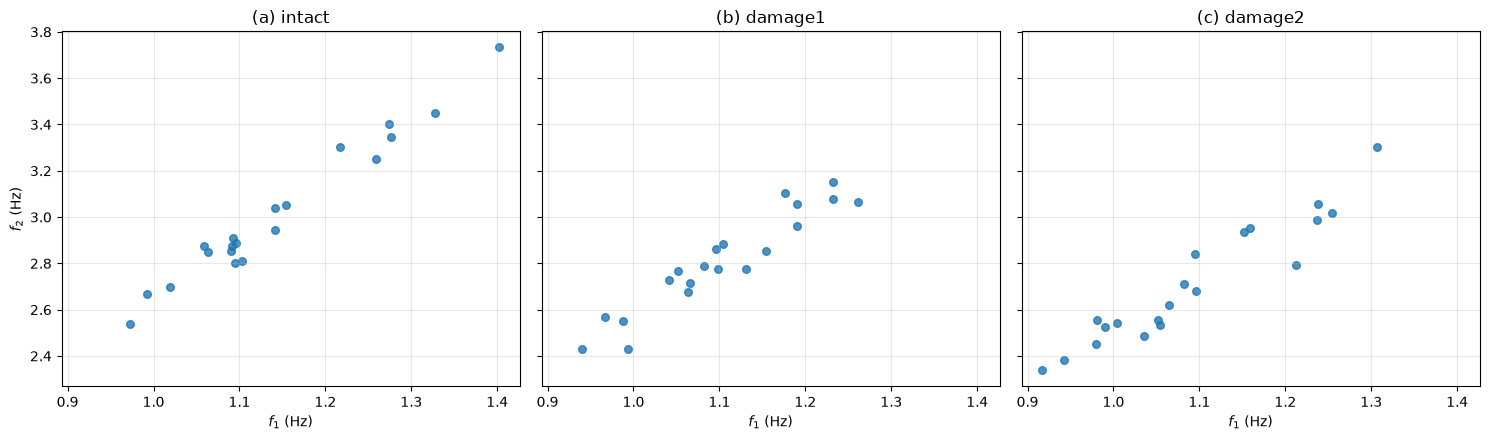

**Figure 1.** Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each scenario: (a) intact, (b) damage1, (c) damage2.

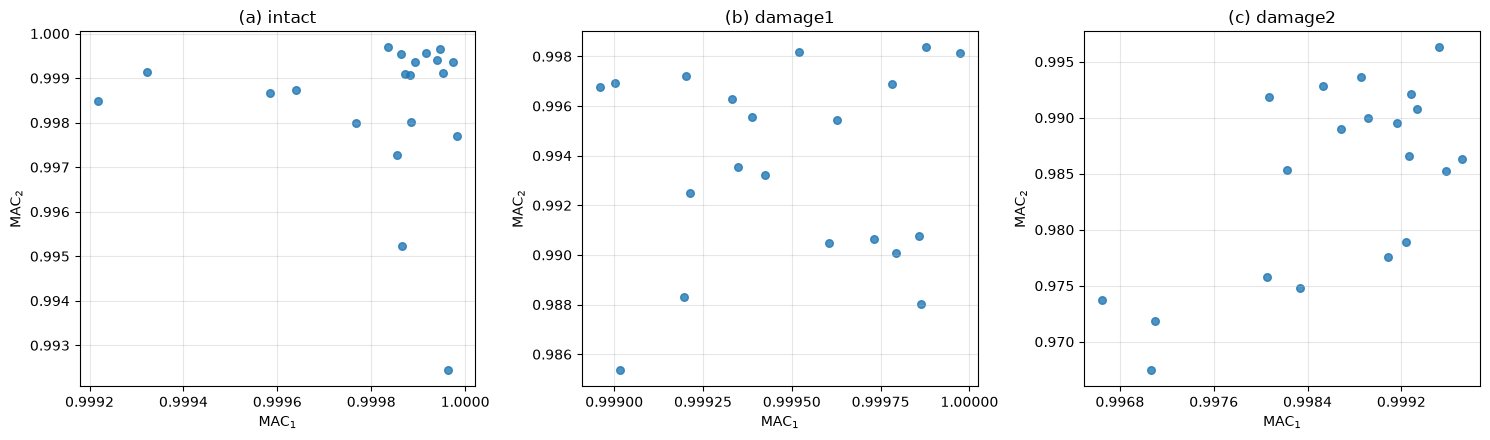

**Figure 2.** MAC of mode 1 ($\mathrm{MAC}_1$) versus MAC of mode 2 ($\mathrm{MAC}_2$) for the 20 measurements of each scenario: (a) intact, (b) damage1, (c) damage2.

In [7]:
# MAC (Eq. 1) of each measured mode shape against the intact reference, for modes 1 and 2
def calculate_MAC(phi_ref, phi_test):
    numerator = np.abs(np.dot(phi_ref, phi_test))**2
    denominator = np.dot(phi_ref, phi_ref) * np.dot(phi_test, phi_test)
    return numerator / denominator


MAC_MODES = [0, 1]                               # mode 1 and mode 2 (indices in MODES)
ref_shapes = shapes['intact'].mean(axis=1)       # (3, 9): mean of the 20 intact shapes of each mode

# mac[scenario]: (N_MEAS, 2) array -> measurements x [MAC1, MAC2]
mac = {sc: np.array([[calculate_MAC(ref_shapes[j], shapes[sc][j, i]) for j in MAC_MODES]
                     for i in range(N_MEAS)])
       for sc in SCENARIOS}

# One table per scenario: rows = MAC of each mode, columns = measurements
for t, sc in enumerate(SCENARIOS, start=6):
    mac_table = pd.DataFrame(mac[sc].T,
                             index=pd.Index([f'MAC{j + 1}' for j in MAC_MODES], name='Mode'),
                             columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(mac_table, t, f'MAC of modes 1 and 2 for each of the 20 measurements, {sc} scenario '
               '(reference: mean intact mode shape).', precision=4)


# Scatter of (f1, f2) for each scenario; same axis limits in all panels to compare them
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
    ax.scatter(freqs[sc][:, 0], freqs[sc][:, 1], s=30, alpha=0.8)
    ax.set_title(f'{label} {sc}')
    ax.set_xlabel('$f_1$ (Hz)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('$f_2$ (Hz)')
fig.tight_layout()
show_figure(fig, 1, 'Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each '
            'scenario: (a) intact, (b) damage1, (c) damage2.', 'part-c', 'C1_f1_f2_scatter.png')

# Scatter of (MAC1, MAC2) for each scenario; each panel scaled to its own data
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
    ax.scatter(mac[sc][:, 0], mac[sc][:, 1], s=30, alpha=0.8)
    ax.set_title(f'{label} {sc}')
    ax.set_xlabel(r'$\mathrm{MAC}_1$')
    ax.set_ylabel(r'$\mathrm{MAC}_2$')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))   # fewer ticks so the labels do not overlap
    ax.grid(alpha=0.3)
fig.tight_layout()
show_figure(fig, 2, r'MAC of mode 1 ($\mathrm{MAC}_1$) versus MAC of mode 2 ($\mathrm{MAC}_2$) for the 20 measurements '
            'of each scenario: (a) intact, (b) damage1, (c) damage2.', 'part-c', 'C1_MAC1_MAC2_scatter.png')

El contorno de la gaussiana de dos variables se calcula a través de la siguiente formula:

$$(\mathbf{x}-\boldsymbol{\mu}_0)^{T}\,\boldsymbol{\Sigma}_0^{-1}\,(\mathbf{x}-\boldsymbol{\mu}_0) = \chi^2_{p,\,1-\alpha}$$

Donde:

- $\mathbf{x}$ es el conjunto de puntos de la linea base.
- $\boldsymbol{\mu}_0$ es el vector de medias de la línea base.
- $\boldsymbol{\Sigma}_0^{-1}$: la inversa de la matriz de covarianza de la línea base.
- $\chi^2_{p,\,1-\alpha}$: el valor de la chi-cuadrado con $p$ grados de libertad, uno por característica, al nivel de confianza $1-\alpha$. Para 2 características al 95 % vale 5.991, y su raíz es 2.45.

Todos los puntos del contorno están a la misma distancia de Mahalanobis del centro. Para dibujarlo se usa la forma paramétrica, que sale de los valores y vectores propios de la covarianza:

$$\boldsymbol{\Sigma}_0 = \mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^{T}, \qquad \mathbf{x}(\theta) = \boldsymbol{\mu}_0 + \sqrt{\chi^2_{p,\,1-\alpha}}\;\mathbf{V}\,\boldsymbol{\Lambda}^{1/2}\begin{bmatrix}\cos\theta\\ \sin\theta\end{bmatrix}$$

Donde:

- $\mathbf{V}$: la matriz de vectores propios, que da la dirección de los ejes de la elipse.
- $\boldsymbol{\Lambda}$: la matriz diagonal de valores propios, con la varianza a lo largo de cada eje.
- $\theta$: el ángulo, de 0 a $2\pi$.

Se toma un círculo de radio 2.45, se estira cada eje según la raíz de su valor propio, se rota con los vectores propios y se traslada al centro.

In [8]:
# Bivariate Gaussian fitted to each feature pair and scenario, and its 95 % contour: d^2 = chi2_0.95(2)
CHI2_95 = stats.chi2.ppf(0.95, df=2)             # 5.991

def gaussian_contour(X, level=CHI2_95, n_points=200):
    mu = X.mean(axis=0)                          # mean of each feature
    cov = np.cov(X, rowvar=False, ddof=1)        # 2x2 covariance matrix
    rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    # Ellipse d^2 = level: axes along the eigenvectors of cov, semi-axes sqrt(level * eigenvalue)
    eigvals, eigvecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, n_points)
    circle = np.vstack([np.cos(t), np.sin(t)])
    ellipse = mu + (eigvecs @ (np.sqrt(level * eigvals)[:, None] * circle)).T
    return {'mu': mu, 'cov': cov, 'rho': rho, 'ellipse': ellipse}


# gauss[pair][scenario]: mean, covariance, rho and (n_points, 2) points of the 95 % ellipse
pairs = {'f1-f2': {sc: freqs[sc][:, :2] for sc in SCENARIOS},
         'MAC1-MAC2': mac}
gauss = {pair: {sc: gaussian_contour(X[sc]) for sc in SCENARIOS} for pair, X in pairs.items()}


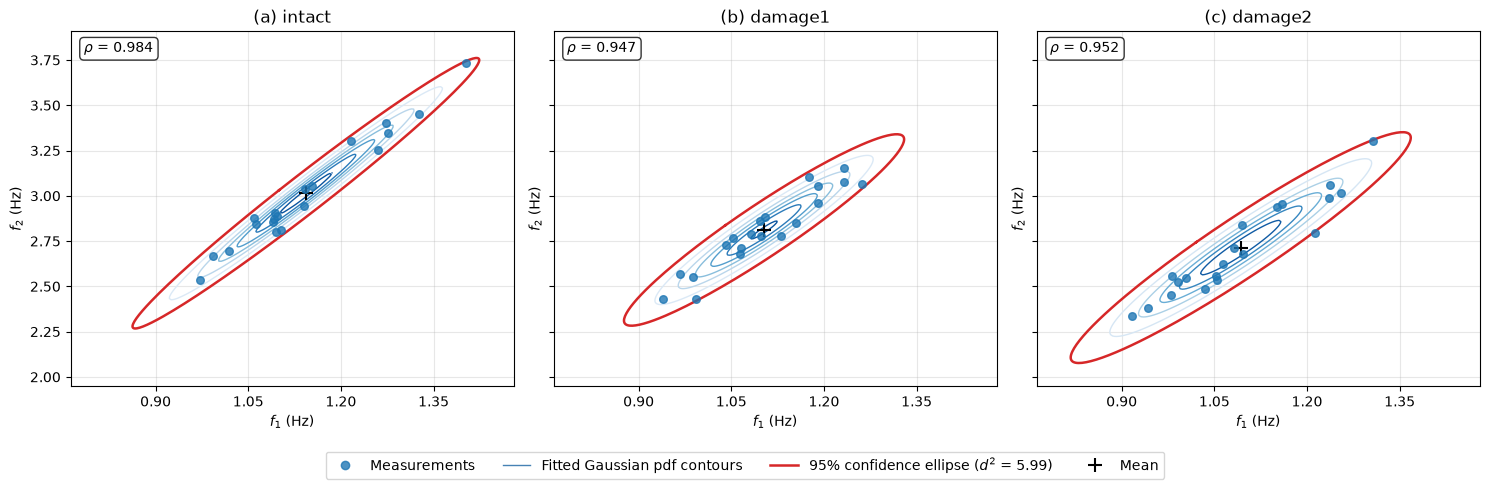

**Figure 3.** Natural frequencies $f_1$ versus $f_2$ with the fitted bivariate Gaussian contours, the 95% confidence ellipse and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.

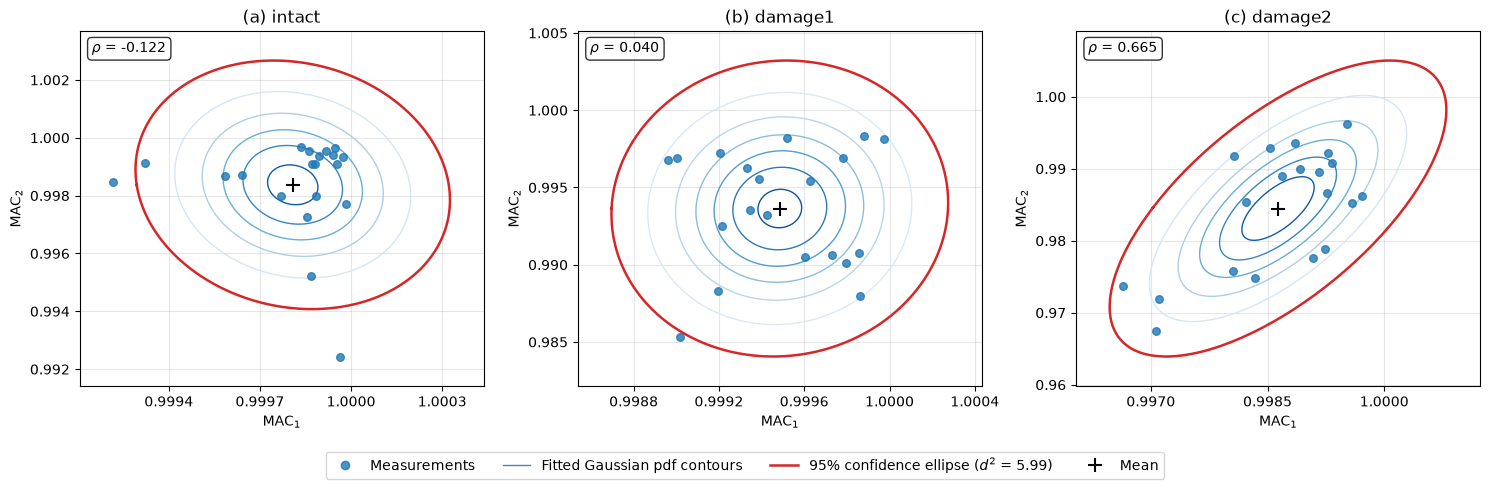

**Figure 4.** $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ with the fitted bivariate Gaussian contours, the 95% confidence ellipse and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.

In [9]:
# Scatter of each feature pair with the fitted bivariate Gaussian contours, the 95 % ellipse and rho
from matplotlib.lines import Line2D

pair_plots = {
    'f1-f2': {'labels': ('$f_1$ (Hz)', '$f_2$ (Hz)'), 'file': 'C1_f1_f2_gaussian.png',
              'caption': 'Natural frequencies $f_1$ versus $f_2$'},
    'MAC1-MAC2': {'labels': (r'$\mathrm{MAC}_1$', r'$\mathrm{MAC}_2$'), 'file': 'C1_MAC1_MAC2_gaussian.png',
                  'caption': r'$\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$'},
}

for n, (pair, cfg) in enumerate(pair_plots.items(), start=3):
    share = pair == 'f1-f2'                      # frequencies on the same axes; MAC panels scaled to their own data
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=share, sharey=share)
    for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
        X, g = pairs[pair][sc], gauss[pair][sc]
        # Grid around the data and the ellipse to evaluate the fitted Gaussian pdf
        pts = np.vstack([X, g['ellipse']])
        lo, hi = pts.min(axis=0), pts.max(axis=0)
        pad = 0.1 * (hi - lo)
        gx, gy = np.meshgrid(np.linspace(lo[0] - pad[0], hi[0] + pad[0], 200),
                             np.linspace(lo[1] - pad[1], hi[1] + pad[1], 200))
        pdf = stats.multivariate_normal(g['mu'], g['cov']).pdf(np.dstack([gx, gy]))
        ax.contour(gx, gy, pdf, levels=6, cmap='Blues', linewidths=1)
        ax.scatter(X[:, 0], X[:, 1], s=30, alpha=0.8, color='tab:blue', zorder=3)
        ax.plot(*g['ellipse'].T, color='tab:red', lw=1.8)
        ax.plot(*g['mu'], 'k+', ms=10, mew=1.5)
        ax.text(0.03, 0.97, rf'$\rho$ = {g["rho"]:.3f}', transform=ax.transAxes, va='top',
                bbox=dict(boxstyle='round', fc='white', alpha=0.8))
        ax.set_title(f'{label} {sc}')
        ax.set_xlabel(cfg['labels'][0])
        ax.set_ylabel(cfg['labels'][1])
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.ticklabel_format(useOffset=False)      # show the actual values, not an offset (+1)
        ax.grid(alpha=0.3)
    handles = [Line2D([], [], ls='', marker='o', color='tab:blue', alpha=0.8, label='Measurements'),
               Line2D([], [], color='steelblue', lw=1, label='Fitted Gaussian pdf contours'),
               Line2D([], [], color='tab:red', lw=1.8, label=r'95% confidence ellipse ($d^2$ = 5.99)'),
               Line2D([], [], ls='', marker='+', color='k', ms=10, mew=1.5, label='Mean')]
    fig.tight_layout()
    fig.legend(handles=handles, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 0.0))
    show_figure(fig, n, f'{cfg["caption"]} with the fitted bivariate Gaussian contours, the 95% confidence ellipse '
                r'and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.',
                'part-c', cfg['file'])


Pending: Discuss: Are (f1, f2) correlated? What about (MAC1, MAC2)? Explain physically why or why not.

### C2. Mahalanobis Distance Detection (8 pts)

Para identificar posibles anomalías para cada par de características y cada escenario de daño, se calcula la distancia de Mahalanobis con la siguiente ecuación:

$$D = \sqrt{(\mathbf{x}-\boldsymbol{\mu}_0)^{T}\,\boldsymbol{\Sigma}_0^{-1}\,(\mathbf{x}-\boldsymbol{\mu}_0)}$$

- $\mathbf{x}$: el vector con las características para cada par de features en los escenarios de daño.
- $\boldsymbol{\mu}_0$: el vector de medias de cada feature de la línea base sana.
- $\boldsymbol{\Sigma}_0^{-1}$: la inversa de la matriz de covarianza de la línea base.

y se compara con el threshold calculado para el escenario intacto con un 95% de confiabilidad ($D_M \approx 2.45$).

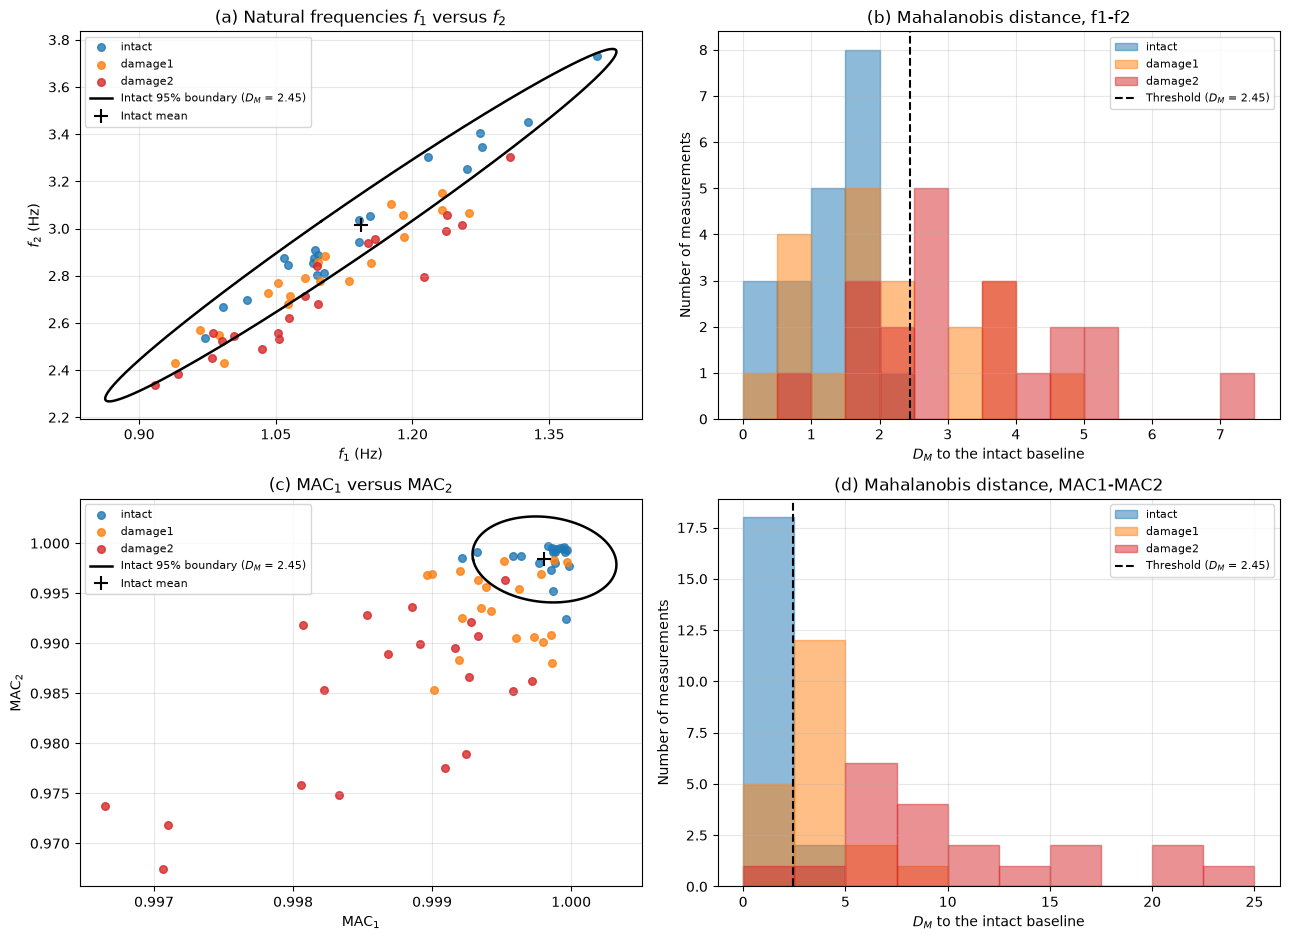

**Figure 5.** Mahalanobis distance detection with the intact scenario as baseline: (a) $f_1$ versus $f_2$ and (c) $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ of the 20 measurements of each scenario with the intact 95% boundary; (b) and (d) histograms of the Mahalanobis distance $D_M$ of each measurement to the intact mean, with the 95% threshold.

In [10]:
# Mahalanobis distance of every measurement to the intact baseline (mean and covariance of the intact scenario)
D_THRESHOLD = np.sqrt(CHI2_95)                   # 2.448: distance on the 95 % intact ellipse

def mahalanobis(X, mu, cov):
    d = X - mu                                   # (n, 2) deviations from the baseline mean
    return np.sqrt(np.einsum('ij,jk,ik->i', d, np.linalg.inv(cov), d))


# dm[pair][scenario]: (N_MEAS,) distance of each measurement to the intact mean
dm = {pair: {sc: mahalanobis(X[sc], gauss[pair]['intact']['mu'], gauss[pair]['intact']['cov'])
             for sc in SCENARIOS}
      for pair, X in pairs.items()}


# Rows: feature pairs. Left: measurements and intact 95 % boundary. Right: histogram of D_M per scenario
colors = dict(zip(SCENARIOS, ['tab:blue', 'tab:orange', 'tab:red']))
BIN_WIDTH = {'f1-f2': 0.5, 'MAC1-MAC2': 2.5}       # width of each D_M range in the histograms
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
for row, (pair, cfg) in enumerate(pair_plots.items()):
    ax_sc, ax_h = axes[row]
    g0 = gauss[pair]['intact']
    for sc in SCENARIOS:
        ax_sc.scatter(*pairs[pair][sc].T, s=30, alpha=0.8, color=colors[sc], label=sc)
    ax_sc.plot(*g0['ellipse'].T, color='k', lw=1.8, label=rf'Intact 95% boundary ($D_M$ = {D_THRESHOLD:.2f})')
    ax_sc.plot(*g0['mu'], 'k+', ms=10, mew=1.5, label='Intact mean')
    ax_sc.set_title(f'({"ac"[row]}) {cfg["caption"]}')
    ax_sc.set_xlabel(cfg['labels'][0])
    ax_sc.set_ylabel(cfg['labels'][1])
    ax_sc.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax_sc.ticklabel_format(useOffset=False)
    ax_sc.grid(alpha=0.3)
    ax_sc.legend(fontsize=8)

    d_max = max(dm[pair][sc].max() for sc in SCENARIOS)
    bins = np.arange(0, d_max + BIN_WIDTH[pair], BIN_WIDTH[pair])
    for sc in SCENARIOS:
        ax_h.hist(dm[pair][sc], bins=bins, alpha=0.5, color=colors[sc], edgecolor=colors[sc], label=sc)
    ax_h.axvline(D_THRESHOLD, color='k', ls='--', lw=1.5, label=f'Threshold ($D_M$ = {D_THRESHOLD:.2f})')
    ax_h.set_title(f'({"bd"[row]}) Mahalanobis distance, {pair}')
    ax_h.set_xlabel('$D_M$ to the intact baseline')
    ax_h.set_ylabel('Number of measurements')
    ax_h.grid(alpha=0.3)
    ax_h.legend(fontsize=8)
fig.tight_layout()
show_figure(fig, 5, 'Mahalanobis distance detection with the intact scenario as baseline: (a) $f_1$ versus $f_2$ and '
            r'(c) $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ of the 20 measurements of each scenario with the intact 95% '
            r'boundary; (b) and (d) histograms of the Mahalanobis distance $D_M$ of each measurement to the intact mean, '
            'with the 95% threshold.', 'part-c', 'C2_mahalanobis.png')

Para reportar los resultados se calcula, para cada par de características y cada escenario, el porcentaje de mediciones que superan el umbral:

$$
\text{Rate} = \frac{\text{Number of measurements with } D_M > 2.45}{\text{Total number of measurements in the scenario}} \times 100\% \tag{2}
$$

El mismo cálculo se interpreta distinto según el escenario:

- **damage1 y damage2:** es la tasa de detección (detection rate), el porcentaje del daño que se detecta correctamente.
- **intact:** es la tasa de falsas alarmas (false alarm rate), el porcentaje del estado sano que se marca como dañado. Con un umbral del 95 % se espera alrededor del 5 %.

In [11]:
# Percentage of measurements above the threshold (Eq. 2): false alarms (intact) and detections (damage)
def rate_text(d):
    k, n = (d > D_THRESHOLD).sum(), len(d)  # measurements above the threshold, total measurements
    return f'{100 * k / n:.0f}% ({k}/{n})'


rates = pd.DataFrame({sc: {pair: rate_text(dm[pair][sc]) for pair in dm} for sc in SCENARIOS})
rates.index.name = 'Feature pair'
rates.columns = ['False alarm rate, intact', 'Detection rate, damage1', 'Detection rate, damage2']
show_table(rates, 9, r'Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) '
           'for each feature pair and scenario.', 'C2_detection_rates.csv', precision=1)

**Table 9.** Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) for each feature pair and scenario.

,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Feature pair,,,
f1-f2,0% (0/20),30% (6/20),70% (14/20)
MAC1-MAC2,10% (2/20),75% (15/20),95% (19/20)


### C3. Bivariate vs Univariate Comparison (5 pts)

Comparison with part B.

**Pending:** Compare Mahalanobis (bivariate) detection rates with z-score (univariate) rates from Part B

**Pending:** Create a comparison table showing detection performance for individual features versus combined
corresponding features

**Pending:** Does accounting for correlation improve detection?

**Pending:** Between frequency pair versus MAC pair: which is more effective for damage detection?

<a id="part-d"></a>
## Part D: Feature Fusion and Engineering (15 pts)

### D1. Systematic Combination Testing (10 pts)

Se genera el diccionario `features` con las matrices de las 6 features para cada escenario (3 escenarios x 20 muestras x 6 features).

In [12]:
# All six features in one matrix per scenario: [f1, f2, f3, MAC1, MAC2, MAC3]
FEATURES = ['f1', 'f2', 'f3', 'MAC1', 'MAC2', 'MAC3']

# MAC (Eq. 1) of the three modes against the mean intact mode shape
mac_all = {sc: np.array([[calculate_MAC(ref_shapes[j], shapes[sc][j, i]) for j in range(len(MODES))]
                         for i in range(N_MEAS)])
           for sc in SCENARIOS}

# features[scenario]: (N_MEAS, 6) array -> measurements x features
features = {sc: np.column_stack([freqs[sc], mac_all[sc]]) for sc in SCENARIOS}

Se estandarizan los valores tomando como linea base las mediciones del escenario intacto con la siguiente ecuación:

agrega la ecuacion de la estandarizacion

In [13]:
# Step 1: mean and standard deviation of each feature in the intact scenario (baseline)
mu0 = features['intact'].mean(axis=0)            # (6,) mean of each feature
sigma0 = features['intact'].std(axis=0, ddof=1)  # (6,) sample standard deviation of each feature

baseline_table = pd.DataFrame({'Mean': mu0, 'Standard deviation': sigma0},
                              index=pd.Index(FEATURES, name='Feature'))
show_table(baseline_table, 10, 'Mean and standard deviation of each feature in the intact scenario '
           '(baseline used for the standardization).', 'D1_intact_baseline.csv', precision=6)

**Table 10.** Mean and standard deviation of each feature in the intact scenario (baseline used for the standardization).

,Mean,Standard deviation
Feature,,
f1,1.143267,0.114653
f2,3.014206,0.305121
f3,4.347781,0.448803
MAC1,0.999808,0.000211
MAC2,0.998374,0.001756
MAC3,0.998017,0.001389


In [14]:
# Step 2: standardize every scenario with the intact statistics: z = (x - mu0) / sigma0
features_std = {sc: (features[sc] - mu0) / sigma0 for sc in SCENARIOS}

# Check: the standardized intact features must have mean 0 and standard deviation 1
assert np.allclose(features_std['intact'].mean(axis=0), 0)
assert np.allclose(features_std['intact'].std(axis=0, ddof=1), 1)
for sc in SCENARIOS:
    print(f'{sc}: mean = {np.round(features_std[sc].mean(axis=0), 2)}, '
          f'std = {np.round(features_std[sc].std(axis=0, ddof=1), 2)}')

intact: mean = [-0. -0. -0. -0.  0. -0.], std = [1. 1. 1. 1. 1. 1.]
damage1: mean = [-0.35 -0.66 -0.35 -1.52 -2.7  -3.15], std = [0.81 0.71 0.74 1.53 2.23 2.82]
damage2: mean = [ -0.44  -0.98  -0.4   -5.55  -7.92 -10.74], std = [0.98 0.85 0.83 4.18 4.78 6.43]


Se generan todas las posibles combinaciones de 4 de 6 features que se pueden tener y se calcula la distancia de Wasserstein tanto para el escenario de daño 1 como el escenario de daño 2 tomando como referencia el escenario intacto.

In [15]:
# All ways to select 4 of the 6 features: C(6, 4) = 15 combinations (column indices in features_std)
from itertools import combinations

combos = list(combinations(range(len(FEATURES)), 4))
combo_names = [', '.join(FEATURES[j] for j in c) for c in combos]   # e.g. 'f1, f2, f3, MAC1'
assert len(combos) == 15

# Multivariate Wasserstein distance between intact and each damage scenario, for each 4-feature combination
DAMAGES = ['damage1', 'damage2']

# w_combo[damage]: (15,) distance of each combination, computed on the standardized features
w_combo = {dmg: np.array([stats.wasserstein_distance_nd(features_std['intact'][:, list(c)],
                                                        features_std[dmg][:, list(c)])
                          for c in combos])
           for dmg in DAMAGES}

w_combo_table = pd.DataFrame({'Features': combo_names,
                              **{f'W (intact, {dmg})': w_combo[dmg] for dmg in DAMAGES}},
                             index=pd.RangeIndex(1, len(combos) + 1, name='Combination'))
show_table(w_combo_table, 11, 'Multivariate Wasserstein distance between the intact scenario and each damage '
           'scenario for the 15 combinations of 4 standardized features.', 'D1_wasserstein_combinations.csv',
           precision=3)

**Table 11.** Multivariate Wasserstein distance between the intact scenario and each damage scenario for the 15 combinations of 4 standardized features.

,Features,"W (intact, damage1)","W (intact, damage2)"
Combination,,,
1,"f1, f2, f3, MAC1",1.872,5.704
2,"f1, f2, f3, MAC2",2.903,8.024
3,"f1, f2, f3, MAC3",3.335,10.822
4,"f1, f2, MAC1, MAC2",3.417,9.925
5,"f1, f2, MAC1, MAC3",3.801,12.382
6,"f1, f2, MAC2, MAC3",4.291,13.432
7,"f1, f3, MAC1, MAC2",3.362,9.886
8,"f1, f3, MAC1, MAC3",3.751,12.348
9,"f1, f3, MAC2, MAC3",4.242,13.400


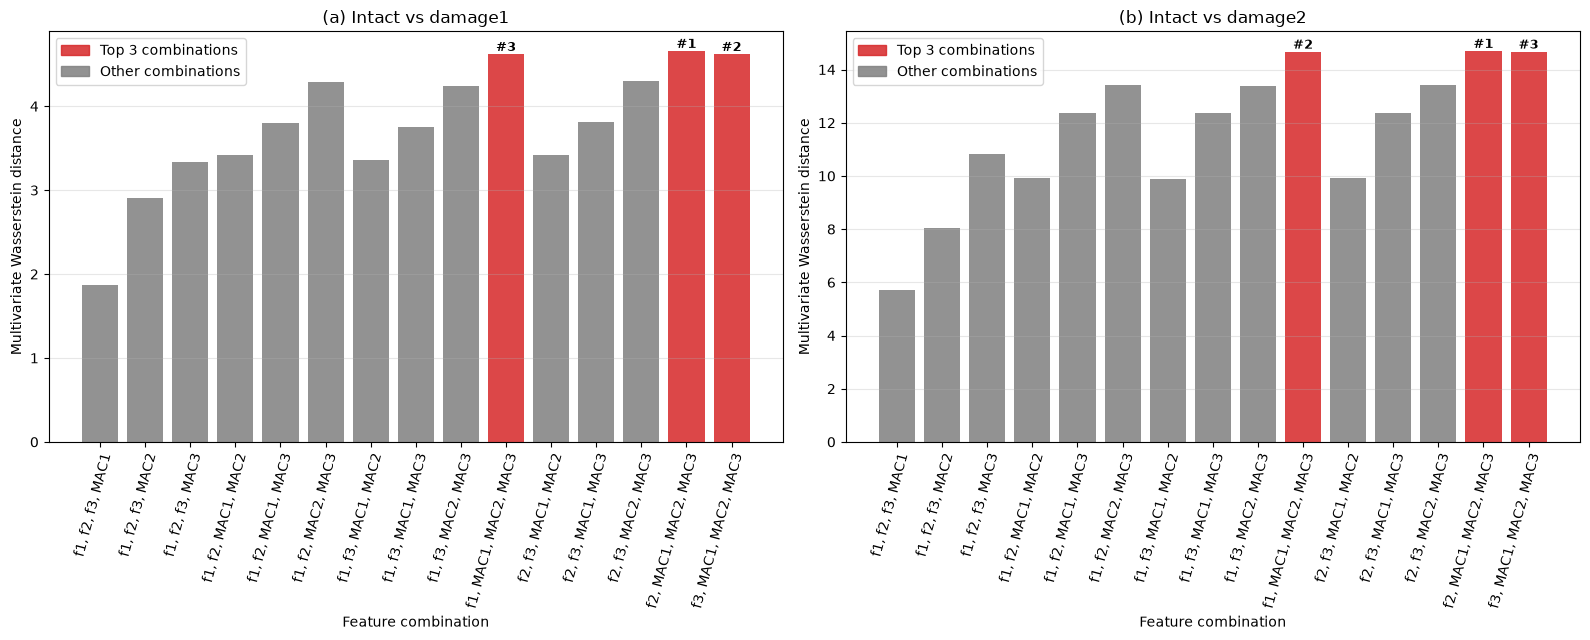

**Figure 6.** Multivariate Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 for the 15 combinations of 4 standardized features. The 3 most sensitive combinations of each scenario are highlighted and ranked.

In [16]:
# Bar chart of the Wasserstein distance of each combination, one panel per damage scenario; top 3 highlighted
from matplotlib.patches import Patch

top3 = {dmg: np.argsort(w_combo[dmg])[::-1][:3] for dmg in DAMAGES}   # indices of the 3 largest distances

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
x = np.arange(len(combos))
for ax, dmg, label in zip(axes, DAMAGES, ['(a)', '(b)']):
    bar_colors = ['tab:red' if k in top3[dmg] else 'tab:gray' for k in x]
    ax.bar(x, w_combo[dmg], color=bar_colors, alpha=0.85)
    for rank, k in enumerate(top3[dmg], start=1):
        ax.text(k, w_combo[dmg][k], f'#{rank}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_xticks(x, combo_names, rotation=75, ha='right', rotation_mode='anchor')
    ax.set_title(f'{label} Intact vs {dmg}')
    ax.set_xlabel('Feature combination')
    ax.set_ylabel('Multivariate Wasserstein distance')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(handles=[Patch(color='tab:red', alpha=0.85, label='Top 3 combinations'),
                       Patch(color='tab:gray', alpha=0.85, label='Other combinations')], loc='upper left')
fig.tight_layout()
show_figure(fig, 6, 'Multivariate Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 for the '
            '15 combinations of 4 standardized features. The 3 most sensitive combinations of each scenario are '
            'highlighted and ranked.', 'part-d', 'D1_wasserstein_combinations.png')

In [17]:
# Top 3 most sensitive combinations (largest Wasserstein distance) for each damage scenario
top3_table = pd.DataFrame(
    {(dmg, col): [val(k) for k in top3[dmg]]
     for dmg in DAMAGES
     for col, val in [('Combination', lambda k: k + 1), ('Features', lambda k: combo_names[k]),
                      ('W', lambda k: w_combo[dmg][k])]},
    index=pd.RangeIndex(1, 4, name='Rank'))
show_table(top3_table, 12, 'Top 3 most sensitive combinations of 4 features (largest multivariate Wasserstein '
           'distance to the intact scenario) for each damage scenario.', 'D1_top3_combinations.csv', precision=3)

**Table 12.** Top 3 most sensitive combinations of 4 features (largest multivariate Wasserstein distance to the intact scenario) for each damage scenario.

### D2. Feature Importance Analysis (5 pts)


Las combinaciones más sensibles al daño son las que incluyen $\text{MAC}_1$, $\text{MAC}_2$ y $\text{MAC}_3$ junto con una de las frecuencias naturales para ambos escenarios de daño. Esto confirma lo encontrado en la parte B2, donde los MAC resultaron más sensibles al daño que las frecuencias naturales. Una variable es más sensible cuando, al ocurrir un cambio en la estructura, varía mucho en comparación con su variación normal en estado intacto.

**Pending waiting for part B**

Frecuencia de aparición: dices qué características están en las combinaciones ganadoras, pero conviene contarlo de forma explícita. Por ejemplo: en las 3 mejores combinaciones de cada daño, los MAC aparecen 3 de 3 veces y cada frecuencia, 1 de 3.

Combinaciones dominadas por frecuencias frente a dominadas por MAC: tu párrafo solo habla de las ganadoras. Falta comparar con las que tienen las tres frecuencias y un solo MAC, y decir cuánto menor es su distancia.

La mejor combinación frente a la mejor característica sola: no aparece. Hay que poner los dos números, la distancia de la mejor combinación y la mejor de la parte B2.

Cuantificar la mejora: tampoco aparece. Por ejemplo, la mejor combinación da X y el mejor MAC solo da Y, una mejora de Z %. Esta comparación es razonable porque en los dos casos las variables están estandarizadas con el intacto, así que las distancias se miden en desviaciones estándar. Aun así, conviene aclarar que una distancia en 4 dimensiones tiende a crecer solo por sumar más dimensiones.

Información independiente o redundante: falta. Aquí entra lo que hablamos: si la mejor combinación casi no supera al mejor MAC solo, las características aportan información redundante, porque los MAC ya contienen casi toda la señal. Puedes apoyarlo con la correlación entre los MAC que calculaste en la parte C.

<a id="part-e"></a>
## Part E: Principal Component Analysis (15 pts)

### E1. PCA Implementation and Variance Analysis (4 pts)

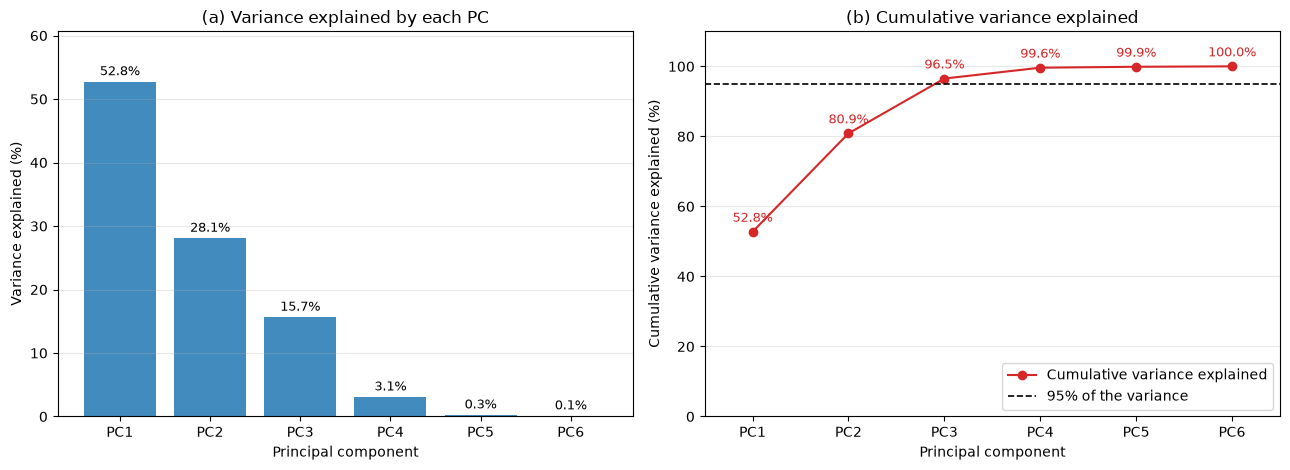

**Figure 7.** Scree plot of the PCA fitted on the 6 standardized features of the intact scenario: (a) variance explained by each principal component and (b) cumulative variance. 3 components are needed to capture 95% of the variance.

In [18]:
# The matrix features_std calculated above is used in this section
from sklearn.decomposition import PCA

# PCA fitted on the standardized intact data only (20 x 6); all 6 components are kept
pca = PCA(n_components=len(FEATURES))
pca.fit(features_std['intact'])

# Scree plot: variance explained by each PC (bars) and cumulative variance (line), with the 95 % level
var_pct = 100 * pca.explained_variance_ratio_
cum_pct = np.cumsum(var_pct)
pcs = np.arange(1, len(var_pct) + 1)
k95 = np.argmax(cum_pct >= 95) + 1               # number of PCs needed to reach 95 % of the variance

# (a) variance explained by each PC, (b) cumulative variance explained with the 95 % level
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.8))
ax_a.bar(pcs, var_pct, color='tab:blue', alpha=0.85)
for p, v in zip(pcs, var_pct):
    ax_a.text(p, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
ax_a.set_ylim(0, 1.15 * var_pct.max())
ax_a.set_title('(a) Variance explained by each PC')
ax_a.set_ylabel('Variance explained (%)')

ax_b.plot(pcs, cum_pct, 'o-', color='tab:red', label='Cumulative variance explained')
ax_b.axhline(95, color='k', ls='--', lw=1.2, label='95% of the variance')
for p, c in zip(pcs, cum_pct):
    ax_b.text(p, c + 2, f'{c:.1f}%', ha='center', va='bottom', fontsize=9, color='tab:red')
ax_b.set_ylim(0, 110)
ax_b.set_xlim(0.5, len(pcs) + 0.5)
ax_b.set_title('(b) Cumulative variance explained')
ax_b.set_ylabel('Cumulative variance explained (%)')
ax_b.legend(loc='lower right')

for ax in (ax_a, ax_b):
    ax.set_xticks(pcs, [f'PC{p}' for p in pcs])
    ax.set_xlabel('Principal component')
    ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
show_figure(fig, 7, 'Scree plot of the PCA fitted on the 6 standardized features of the intact scenario: (a) variance '
            f'explained by each principal component and (b) cumulative variance. {k95} components are needed to capture '
            '95% of the variance.', 'part-e', 'E1_scree_plot.png')

Como se puede observar en la figura 7, se necesitan al menos los primeros 3 componentes para representar el 95% de la varianza de los datos.

### E2. First Principal Component Analysis (3 pts)

Se proyectan los datos de las 6 variables sobre la componente 1 del PCA para cada uno de los escenarios.

In [19]:
# Project the standardized features of every scenario onto PC1 only (PCA fitted on the intact data)
# pc1[scenario]: (N_MEAS,) score of each measurement on the first principal component
pc1 = {sc: pca.transform(features_std[sc])[:, 0] for sc in SCENARIOS}

for sc in SCENARIOS:
    print(f'{sc}: {pc1[sc].shape[0]} PC1 scores, mean = {pc1[sc].mean():.3f}, std = {pc1[sc].std(ddof=1):.3f}')

intact: 20 PC1 scores, mean = 0.000, std = 1.779
damage1: 20 PC1 scores, mean = 0.231, std = 1.503
damage2: 20 PC1 scores, mean = 1.970, std = 2.512


Es importante notar que, aunque los datos se estandarizaron con el escenario intacto ($\mu = 0$ y $\sigma = 1$ para cada característica), la varianza total es 6, es decir, la suma de las varianzas de las seis características. Como el componente 1 del PCA representa el 52.8 % de esa varianza total, su varianza es $0.528 \times 6 \approx 3.17$ y su desviación estándar es $\sqrt{3.17} \approx 1.78$. Por eso la desviación estándar de PC1 es mayor que 1: concentra la variación que comparten las características correlacionadas.

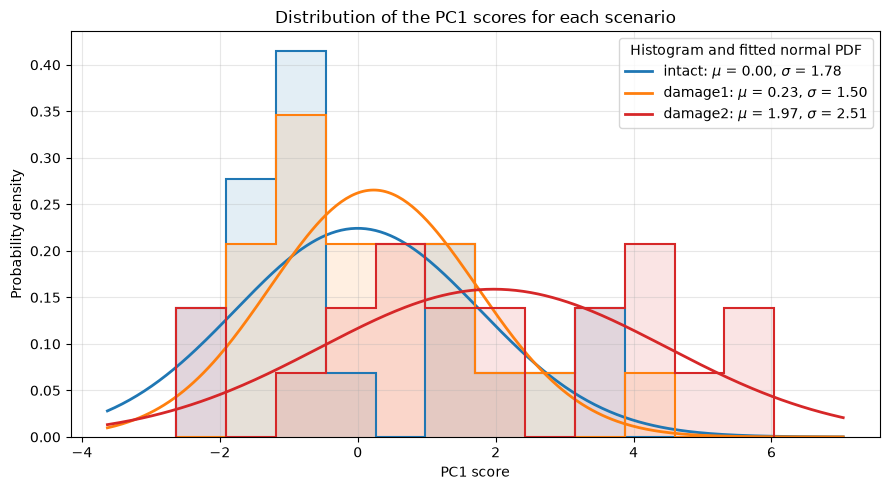

**Figure 8.** Overlaid histograms of the PC1 scores of the intact, damage1 and damage2 scenarios, with the normal PDF fitted to each scenario (mean $\mu$ and standard deviation $\sigma$ in the legend). PCA fitted on the standardized intact data.

In [20]:
# Overlaid histograms of the PC1 scores of the three scenarios, each with its fitted normal PDF
all_pc1 = np.concatenate([pc1[sc] for sc in SCENARIOS])
bins = np.linspace(all_pc1.min(), all_pc1.max(), 13)   # same bins for the three scenarios
x_pdf = np.linspace(all_pc1.min() - 1, all_pc1.max() + 1, 300)

fig, ax = plt.subplots(figsize=(9, 5))
for sc in SCENARIOS:
    mu, sd = pc1[sc].mean(), pc1[sc].std(ddof=1)
    ax.hist(pc1[sc], bins=bins, density=True, alpha=0.12, color=colors[sc])
    ax.hist(pc1[sc], bins=bins, density=True, histtype='step', lw=1.5, color=colors[sc])
    ax.plot(x_pdf, stats.norm.pdf(x_pdf, mu, sd), color=colors[sc], lw=2,
            label=rf'{sc}: $\mu$ = {mu:.2f}, $\sigma$ = {sd:.2f}')
ax.set_title('Distribution of the PC1 scores for each scenario')
ax.set_xlabel('PC1 score')
ax.set_ylabel('Probability density')
ax.grid(alpha=0.3)
ax.legend(title='Histogram and fitted normal PDF')
fig.tight_layout()
show_figure(fig, 8, 'Overlaid histograms of the PC1 scores of the intact, damage1 and damage2 scenarios, with the normal '
            r'PDF fitted to each scenario (mean $\mu$ and standard deviation $\sigma$ in the legend). PCA fitted on the '
            'standardized intact data.', 'part-e', 'E2_PC1_distributions.png')

In [21]:
# 1D Wasserstein distance between the PC1 scores of the intact scenario and each damage scenario
w_pc1 = {dmg: stats.wasserstein_distance(pc1['intact'], pc1[dmg]) for dmg in DAMAGES}

w_pc1_table = pd.DataFrame({f'W (intact, {dmg})': [w_pc1[dmg]] for dmg in DAMAGES},
                           index=pd.Index(['PC1'], name='PCA space'))
show_table(w_pc1_table, 13, 'Wasserstein distance $W_1$ between the PC1 scores of the intact scenario and each damage '
           'scenario.', 'E2_wasserstein_PC1.csv', precision=3)

**Table 13.** Wasserstein distance $W_1$ between the PC1 scores of the intact scenario and each damage scenario.

,"W (intact, damage1)","W (intact, damage2)"
PCA space,,
PC1,0.479,1.970


**PENDING:** Compare with Part B results: is PC1 more sensitive than any single feature?

### E3. Two-Dimensional PCA Space (3 pts)

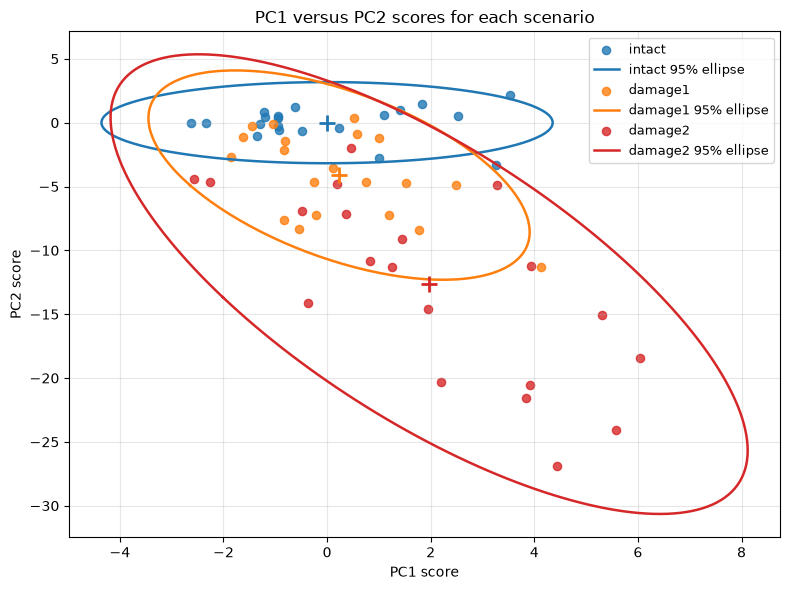

**Figure 9.** Scores of the 20 measurements of each scenario on the first two principal components (PC1 versus PC2), with the 95% confidence ellipse of the bivariate Gaussian fitted to each scenario (+: mean). PCA fitted on the standardized intact data.

In [22]:
# Project the standardized features of every scenario onto PC1 and PC2 (PCA fitted on the intact data)
# pc12[scenario]: (N_MEAS, 2) array -> measurements x [PC1, PC2]
pc12 = {sc: pca.transform(features_std[sc])[:, :2] for sc in SCENARIOS}

# Bivariate Gaussian fitted to the PC1-PC2 scores of each scenario and its 95 % contour (gaussian_contour from C1)
gauss_pc = {sc: gaussian_contour(pc12[sc]) for sc in SCENARIOS}

# Scatter of PC1 versus PC2 with the 95 % ellipse and the mean of each scenario
fig, ax = plt.subplots(figsize=(8, 6))
for sc in SCENARIOS:
    ax.scatter(*pc12[sc].T, s=35, alpha=0.8, color=colors[sc], label=sc)
    ax.plot(*gauss_pc[sc]['ellipse'].T, color=colors[sc], lw=1.8, label=f'{sc} 95% ellipse')
    ax.plot(*gauss_pc[sc]['mu'], '+', color=colors[sc], ms=12, mew=2)
ax.set_title('PC1 versus PC2 scores for each scenario')
ax.set_xlabel('PC1 score')
ax.set_ylabel('PC2 score')
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
show_figure(fig, 9, 'Scores of the 20 measurements of each scenario on the first two principal components (PC1 versus '
            'PC2), with the 95% confidence ellipse of the bivariate Gaussian fitted to each scenario (+: mean). '
            'PCA fitted on the standardized intact data.', 'part-e', 'E3_PC1_PC2_scatter.png')

Se verifica que el coeficiente de correlación entre PC1 y PC2 en el escenario intacto sea cero. Esto es lo esperado, porque el PCA se ajustó con los datos de ese escenario y sus componentes, por construcción, tienen covarianza nula entre sí, es decir, no están correlacionados.

In [23]:
# Correlation coefficient between PC1 and PC2 for the intact data (must be 0: fundamental PCA property)
rho_pc12 = np.corrcoef(pc12['intact'][:, 0], pc12['intact'][:, 1])[0, 1]
print(f'Correlation coefficient between PC1 and PC2 (intact): rho = {rho_pc12:.2e}')

Correlation coefficient between PC1 and PC2 (intact): rho = 3.67e-17


In [24]:
# 2D Wasserstein distance between the PC1-PC2 scores of the intact scenario and each damage scenario
w_pc12 = {dmg: stats.wasserstein_distance_nd(pc12['intact'], pc12[dmg]) for dmg in DAMAGES}

w_pc12_table = pd.DataFrame({f'W (intact, {dmg})': [w_pc12[dmg]] for dmg in DAMAGES},
                            index=pd.Index(['PC1-PC2'], name='PCA space'))
show_table(w_pc12_table, 14, 'Two-dimensional Wasserstein distance between the PC1-PC2 scores of the intact scenario '
           'and each damage scenario.', 'E3_wasserstein_PC1_PC2.csv', precision=3)

**Table 14.** Two-dimensional Wasserstein distance between the PC1-PC2 scores of the intact scenario and each damage scenario.

,"W (intact, damage1)","W (intact, damage2)"
PCA space,,
PC1-PC2,4.175,12.809


**PENDING:** Compare with PC1-only result: does adding PC2 improve detection sensitivity?

### E4. Progressive Dimensionality Impact (3 pts)

In [25]:
# Scores of every scenario on all 6 PCs (PCA fitted on the intact data)
# pc_all[scenario]: (N_MEAS, 6) array -> measurements x [PC1, ..., PC6]
pc_all = {sc: pca.transform(features_std[sc]) for sc in SCENARIOS}

# Wasserstein distance between intact and each damage scenario using the first k PCs, k = 1, ..., 6
K = np.arange(1, len(FEATURES) + 1)
w_k = {dmg: np.array([stats.wasserstein_distance_nd(pc_all['intact'][:, :k], pc_all[dmg][:, :k]) for k in K])
       for dmg in DAMAGES}

w_k_table = pd.DataFrame({f'W (intact, {dmg})': w_k[dmg] for dmg in DAMAGES},
                         index=pd.Index(K, name='Number of PCs k'))
show_table(w_k_table, 15, 'Wasserstein distance between the intact scenario and each damage scenario using the first '
           '$k$ principal components, $k$ = 1, ..., 6.', 'E4_wasserstein_k_PCs.csv', precision=3)

**Table 15.** Wasserstein distance between the intact scenario and each damage scenario using the first $k$ principal components, $k$ = 1, ..., 6.

,"W (intact, damage1)","W (intact, damage2)"
Number of PCs k,,
1,0.479,1.970
2,4.175,12.809
3,4.707,14.601
4,4.750,14.733
5,4.758,14.738
6,4.764,14.742


**PENDING:** Identify optimal k: where does detection sensitivity plateau?

**PENDING:** Compare 6-PC result with full 6D features (no PCA): are they identical? Why?

### E5. Physical Interpretation (2 pts)

<a id="part-f"></a>
## Part F: Engineering Insights (5 pts)

### F1. Method Comparison and Selection (2 pts)

### F2. Feature Selection Strategy (2 pts)

### F3. Practical Implementation Considerations (1 pt)

<a id="ai-note"></a>
## Use of Generative AI